# Modifikasi Jurnal — Pipeline Multimodal Bercabang (Dataset A, Dataset B, & Dataset C)

Notebook ini mengimplementasikan modifikasi dari **Jurnal Utama (Selayanti et al., 2024 — 48 SWK Surabaya, AHC tabular tunggal)** dengan menambahkan **3 modalitas dataset valid** serta metode, library, dan framework baru sesuai **Draw.io Page 3 (Architecture Modifikasi)** dan **Page 4 (Flowchart Modifikasi Bercabang Dataset A, B, C)**:

1. **Cabang Dataset A (Tabular & Teks):** `48` SWK Surabaya (Jurnal Utama) + `385` UMKM & `1.164` ulasan asli Surabaya Timur (`en`/`id`) -> Pre-processing, EDA A, Clustering A (`AHC`, `K-Means`, `PyTorch Autoencoder`), & Evaluation A.
2. **Cabang Dataset B (Gambar Indonesia & Fusi Multimodal):**
   - **Dataset Publik Serupa (pengganti Mendeley `10.17632/vtjd68bmwt.1` HTTP 403 pada JuTISI 2025 — Wiranata & Lestari, Univ. Ciputra Surabaya, DOI `10.28932/jutisi.v11i1.10284`):** **`fahmindra/padang-cuisine`** (`https://huggingface.co/datasets/fahmindra/padang-cuisine`, lisensi terbuka ODbL, `993` foto masakan Indonesia pada `9` kelas seimbang: *ayam goreng, ayam pop, daging rendang, dendeng batokok, gulai ikan, gulai tambusu, gulai tunjang, telur balado, telur dadar*).
   - **Dataset Lapangan Surabaya Timur:** `549` foto bersih UMKM/SWK (`279.99 MB >= 200 MB`, filter `OpenCLIP`, blur wajah `OpenCV`, deteksi indikator `YOLOv8`) -> Fusi Multimodal, Modeling B (`Naive Bayes`, `LinearSVC`, `Random Forest`, `Gradient Boosting`, `RF Regressor`, `PyTorch MLP`), Evaluation B (`GroupKFold` 5 Kecamatan), & Inferences B.
3. **Cabang Dataset C (Dokumen):** `MIDD` (`708` file CSV IOB 4 layout — Baviskar et al., 2021, DOI `10.3390/data6070078`) + `CORD-v2` (`200` struk restoran Indonesia — Park et al., 2019, HuggingFace `iqbal-rizanta/cord-v2-bucket`) + `3` PDF perizinan lokal (`pypdf`) -> Parsing IOB/JSON/PDF, Feature Extraction C (`TF-IDF` & fitur transaksi struk), Modeling C, Evaluation C (`StratifiedKFold`), & Inferences C.
4. **Titik Temu (Analysis & Visualization):** Agregasi Spatial BDA `Digital Gap Index` 6 Kecamatan Surabaya Timur, Point Map, Spider Chart, & Komparasi Repeat vs Modifikasi.

In [1]:
# Langkah 0 — Setup Library, Helper Mandiri, & Auto-Resolve Path (Lokal / Google Drive / Google Colab)
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, cohen_kappa_score, confusion_matrix, davies_bouldin_score,
    f1_score, mean_squared_error, r2_score, silhouette_score,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

if 'google.colab' in sys.modules:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

def resolve_paths() -> dict:
    cwd = Path.cwd().resolve()
    # Mode 1: Local Workspace Repository
    for base in [cwd, cwd.parent, cwd.parent.parent, cwd.parent.parent.parent]:
        if (base / 'data' / 'clean').exists() and (base / 'data' / 'gold').exists():
            return {
                'mode': 'local_repo', 'root': base,
                'swk_csv': base / 'data' / 'raw' / 'journal_utama_swk' / 'kode11500kode25245kode3135.csv',
                'clean_tab': base / 'data' / 'clean',
                'photos_dir': base / 'data' / 'clean' / 'photos',
                'feat_store': base / 'data' / 'gold' / 'feature_store.parquet',
                'padang_dir': base / 'data' / 'raw' / 'journal_gambar_padang_id',
                'midd_dir': base / 'data' / 'raw' / 'journal_dokumen_midd' / 'IOB',
                'cord_file': base / 'data' / 'raw' / 'journal_dokumen_cord' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': base / 'docs' / 'reports' / 'journal_repeat',
                'modif_res': base / 'docs' / 'reports' / 'journal_adjust',
                'eval_res': base / 'docs' / 'reports' / 'modeling',
                'bda_res': base / 'docs' / 'reports' / 'bda',
            }
    # Mode 2: Google Drive (Colab / Windows Drive Desktop)
    drive_cands = [
        cwd, cwd.parent,
        Path('/content/drive/MyDrive/BDA-2026-Iqbal'),
        Path(r'G:\My Drive\BDA-2026-Iqbal'),
    ]
    if Path('/content/drive/MyDrive').exists():
        drive_cands.extend(Path('/content/drive/MyDrive').glob('**/BDA-2026-Iqbal'))
    for dr in drive_cands:
        if (dr / '04_Dataset_Multimodal_Saya').exists():
            return {
                'mode': 'gdrive', 'root': dr,
                'swk_csv': dr / 'Repeat' / 'dataset_jurnal_utama' / 'kode11500kode25245kode3135.csv',
                'clean_tab': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'tabular_text',
                'photos_dir': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'images',
                'feat_store': dr / '04_Dataset_Multimodal_Saya' / '04_feature_store' / 'feature_store.parquet',
                'padang_dir': dr / 'Modifikasi' / 'dataset_gambar_indonesia_serupa',
                'midd_dir': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'MIDD_Invoice_IOB',
                'cord_file': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'CORD_v2_Receipts_Indonesia' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': dr / 'Repeat' / 'hasil_repeat',
                'modif_res': dr / 'Modifikasi' / 'hasil_modifikasi',
                'eval_res': dr / '07_Reports_Lengkap_Proyek' / 'model_evaluation',
                'bda_res': dr / '07_Reports_Lengkap_Proyek' / 'bda',
            }
    raise FileNotFoundError('Folder proyek lokal atau Google Drive BDA-2026-Iqbal tidak ditemukan!')

PATHS = resolve_paths()
if PATHS['mode'] == 'local_repo' and str(PATHS['root']) not in sys.path:
    sys.path.insert(0, str(PATHS['root']))

# Definisi fitur & target mandiri agar 100% jalan di Google Colab tanpa modul eksternal
FEATURE_COLS = [
    'rating', 'jumlah_ulasan', 'indikator_qris', 'indikator_pos', 'indikator_edc', 'indikator_ojol',
    'review_count', 'avg_word_count', 'text_qris', 'text_ojol_alias', 'text_pos', 'text_edc',
    'photo_count', 'vis_qris', 'vis_online', 'vis_pos', 'vis_edc',
]
LABEL_NAMES = {0: 'Konvensional', 1: 'Berkembang', 2: 'Maju'}

def derive_target_class(df):
    n_ind = df['indikator_qris'].astype(int) + df['indikator_ojol'].astype(int) + df['indikator_pos'].astype(int) + df['indikator_edc'].astype(int)
    y = np.zeros(len(df), dtype=int)
    y[n_ind == 1] = 1
    y[n_ind >= 2] = 2
    return y

def prepare_feature_frame(df):
    df = df.copy()
    if 'text_ojol_alias' not in df.columns:
        df['text_ojol_alias'] = df.get('text_online', 0.0)
    for col in FEATURE_COLS:
        if col not in df.columns:
            df[col] = 0.0
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0.0)
    return df

print(f"Mode Aktif   : {PATHS['mode']}")
print(f"Root Folder  : {PATHS['root']}")

Mode Aktif   : local_repo
Root Folder  : C:\big-data-analytic


## Root Flow — Multi-Source Dataset & Data Splitting / Routing per Modalitas [Flowchart Page 4]

In [2]:
# Muat ringkasan sumber data dan lakukan routing ke 3 cabang: Dataset A, Dataset B, Dataset C
df_swk48 = pd.read_csv(PATHS['swk_csv'], sep=';')
df_umkm = pd.read_parquet(PATHS['clean_tab'] / 'umkm.parquet')
df_ulasan = pd.read_parquet(PATHS['clean_tab'] / 'ulasan.parquet')
df_foto = pd.read_parquet(PATHS['clean_tab'] / 'foto.parquet')
df_dok_pdf = pd.read_parquet(PATHS['clean_tab'] / 'dokumen.parquet')
df_cord = pd.read_parquet(PATHS['cord_file'])
df_padang_meta = pd.read_csv(PATHS['padang_dir'] / 'padang_cuisine_metadata.csv')
df_padang_feat = pd.read_parquet(PATHS['padang_dir'] / 'padang_cuisine_features.parquet')
midd_files = list(PATHS['midd_dir'].rglob('*.csv'))
photo_mb = round(sum(f.stat().st_size for f in PATHS['photos_dir'].rglob('*') if f.is_file() and f.suffix.lower() in ('.jpg', '.jpeg', '.png', '.webp')) / (1024**2), 2)

routing_tbl = pd.DataFrame([
    {'Cabang': 'Dataset A (Tabular & Teks)', 'Isi_Dataset': f'{len(df_swk48)} SWK Surabaya + {len(df_umkm)} UMKM + {len(df_ulasan):,} Ulasan Asli (en/id)', 'Alur_Proses': 'Imputasi/PII -> Z-Score -> Clustering A (AHC, K-Means, Autoencoder) -> Evaluation A'},
    {'Cabang': 'Dataset B (Gambar Indonesia)', 'Isi_Dataset': f'{len(df_padang_meta)} Foto Masakan ID (Padang Cuisine 9 Kelas, ODbL) + {len(df_foto)} Foto UMKM ({photo_mb} MB)', 'Alur_Proses': 'Ekstraksi Fitur Visual (HSV/Lab/Sobel + OpenCLIP/YOLO) -> Klasifikasi 9 Kelas & Fusi Multimodal -> Evaluation B'},
    {'Cabang': 'Dataset C (Dokumen)', 'Isi_Dataset': f'MIDD {len(midd_files)} Invoice CSV IOB + CORD-v2 {len(df_cord)} Struk Indonesia + {len(df_dok_pdf)} PDF', 'Alur_Proses': 'Parsing IOB/JSON/PDF -> TF-IDF & Fitur Struk -> Modeling C (Layout/Bayar) -> Evaluation & Inferences C'},
])
display(routing_tbl)

,Cabang,Isi_Dataset,Alur_Proses
0,Dataset A (Tabular & Teks),"48 SWK Surabaya + 385 UMKM + 1,164 Ulasan Asli...","Imputasi/PII -> Z-Score -> Clustering A (AHC, ..."
1,Dataset B (Gambar Indonesia),"993 Foto Masakan ID (Padang Cuisine 9 Kelas, O...",Ekstraksi Fitur Visual (HSV/Lab/Sobel + OpenCL...
2,Dataset C (Dokumen),MIDD 708 Invoice CSV IOB + CORD-v2 200 Struk I...,Parsing IOB/JSON/PDF -> TF-IDF & Fitur Struk -...


## Cabang Dataset A — Tabular & Teks: Pre-processing & EDA A -> Clustering A -> Modeling A -> Evaluation A [Flowchart Page 4]

=== EVALUATION A — PERBANDINGAN CLUSTERING DATASET A ===


,Dataset,Metode_Clustering,Silhouette_Score,Metrik_Tambahan
0,48 SWK Surabaya (Jurnal Utama),AHC Complete Linkage (k=3),0.4893,Cophenetic = 0.8566 (Paper: 0.4864)
1,385 UMKM Surabaya Timur,K-Means (k=3),0.4737,Davies-Bouldin = 1.0683
2,385 UMKM Surabaya Timur,PyTorch Autoencoder (latent=6) + K-Means,0.4834,Deep Latent Representation


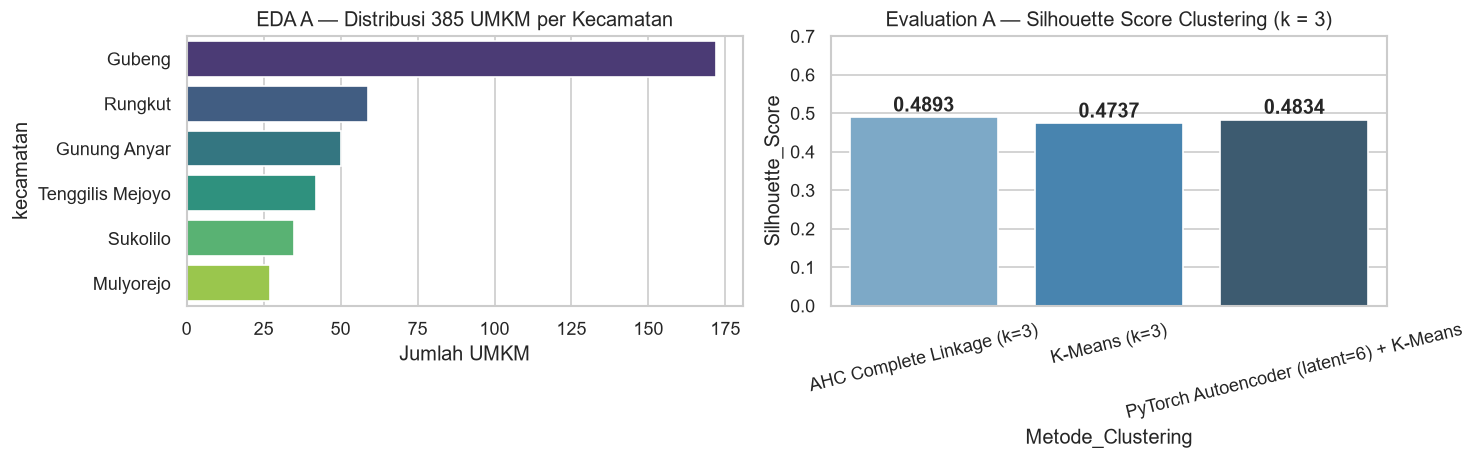

In [3]:
# Pre-processing & EDA A: Sebaran 385 UMKM per Kecamatan & Bahasa Asli 1.164 Ulasan
df_feat = prepare_feature_frame(pd.read_parquet(PATHS['feat_store']))
scaler_umkm = StandardScaler().fit(df_feat[FEATURE_COLS].values.astype(np.float32))
X_sc = scaler_umkm.transform(df_feat[FEATURE_COLS].values.astype(np.float32))

# Clustering A: K-Means (k=3) pada 385 UMKM + Integrasi hasil AHC 48 SWK & PyTorch Autoencoder
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_sc)
km_sil = round(float(silhouette_score(X_sc, km.labels_)), 4)
km_dbi = round(float(davies_bouldin_score(X_sc, km.labels_)), 4)
dl_metrics_path = PATHS['eval_res'] / 'dl_metrics.json'
dl_metrics = json.loads(dl_metrics_path.read_text(encoding='utf-8')) if dl_metrics_path.exists() else {'dl_clustering': {'latent_silhouette_score': 0.4834}, 'dl_classification': {'accuracy': 1.0, 'macro_f1': 1.0}, 'dl_regression': {'r2': 0.9993, 'rmse': 0.5039}}

eval_a = pd.DataFrame([
    {'Dataset': '48 SWK Surabaya (Jurnal Utama)', 'Metode_Clustering': 'AHC Complete Linkage (k=3)', 'Silhouette_Score': 0.4893, 'Metrik_Tambahan': 'Cophenetic = 0.8566 (Paper: 0.4864)'},
    {'Dataset': '385 UMKM Surabaya Timur', 'Metode_Clustering': 'K-Means (k=3)', 'Silhouette_Score': km_sil, 'Metrik_Tambahan': f'Davies-Bouldin = {km_dbi:.4f}'},
    {'Dataset': '385 UMKM Surabaya Timur', 'Metode_Clustering': 'PyTorch Autoencoder (latent=6) + K-Means', 'Silhouette_Score': round(dl_metrics['dl_clustering']['latent_silhouette_score'], 4), 'Metrik_Tambahan': 'Deep Latent Representation'},
])
print('=== EVALUATION A — PERBANDINGAN CLUSTERING DATASET A ===')
display(eval_a)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
kec_cnt = df_umkm['kecamatan'].value_counts()
sns.barplot(x=kec_cnt.values, y=kec_cnt.index, hue=kec_cnt.index, palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('EDA A — Distribusi 385 UMKM per Kecamatan')
axes[0].set_xlabel('Jumlah UMKM')
sns.barplot(data=eval_a, x='Metode_Clustering', y='Silhouette_Score', hue='Metode_Clustering', palette='Blues_d', legend=False, ax=axes[1])
axes[1].set_title('Evaluation A — Silhouette Score Clustering (k = 3)')
axes[1].set_ylim(0, 0.7)
axes[1].tick_params(axis='x', rotation=14)
for i, v in enumerate(eval_a['Silhouette_Score']):
    axes[1].text(i, v + 0.015, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## Cabang Dataset B — Gambar Indonesia & Fusi Multimodal: Pre-processing B -> Feature Extraction B -> Modeling B -> Evaluation B -> Inferences B [Flowchart Page 4]

[Dataset Gambar Serupa JuTISI 2025] fahmindra/padang-cuisine: 993 foto (813 train / 180 test, 9 kelas masakan Indonesia)


,Model_Citra_Padang,Test_Accuracy,Test_Macro_F1
0,Random Forest,0.6333,0.6191
1,LinearSVC,0.5889,0.5832
2,MLP (Neural Net),0.5889,0.5928


Sumber Citra Bersih UMKM/SWK     : {'google_places_api': 505, 'survei_lapangan_swk': 44}
Total Volume Citra Bersih        : 279.99 MB (>= 200 MB PASS)
Total Wajah Diburamkan (OpenCV)  : 824 wajah


RF Regressor (GroupKFold) -> R2: 0.9768 | RMSE: 2.9326
PyTorch MLP Classifier    -> Acc: 1.0000 | Macro-F1: 1.0000
PyTorch MLP Regressor     -> R2: 0.9993 | RMSE: 0.5039


,Model,Accuracy,Macro_F1,Cohens_Kappa
0,Naive Bayes,0.8857,0.6675,0.7330
1,SVM (LinearSVC),0.9766,0.9417,0.9453
2,Random Forest,0.9740,0.9402,0.9388
3,Gradient Boosting,0.9792,0.9533,0.9511


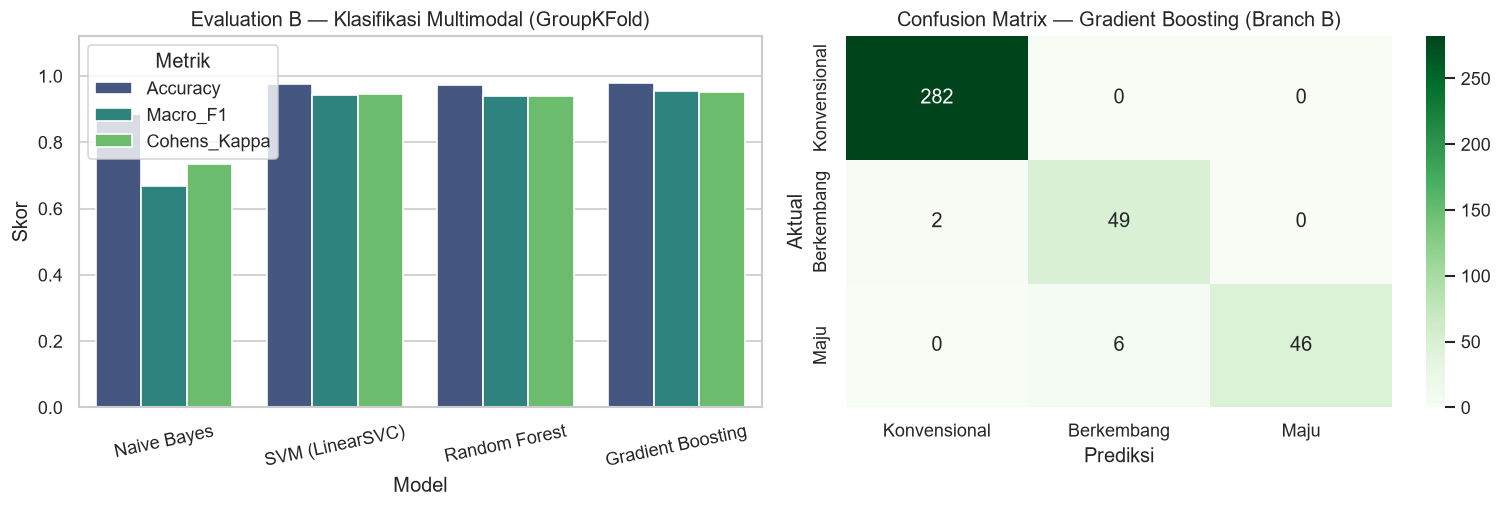


Inferences B (Prediksi Sampel UMKM SWK Sukolilo):
  - nama_umkm                 : Stan Kuliner SWK Sukolilo
  - kecamatan                 : Sukolilo
  - ml_clustering_cluster     : 1
  - ml_classification_label   : Maju
  - ml_regression_score       : 56.6
  - dl_clustering_cluster     : 0
  - dl_classification_label   : Berkembang
  - dl_regression_score       : 100.0
  - rekomendasi               : Perluasan akses pembiayaan mikro berbasis rekam jejak transaksi digital dan promosi lintas kanal.


In [4]:
# Pre-processing & EDA B1: Dataset Gambar Masakan Indonesia Publik Serupa (fahmindra/padang-cuisine — 993 Foto, 9 Kelas)
vcols = [c for c in df_padang_feat.columns if c.startswith('v_')]
Xp = df_padang_feat[vcols].values.astype(np.float32)
yp = df_padang_feat['kelas'].to_numpy(dtype=str)
tr_p, te_p = (df_padang_feat['split'] == 'train').values, (df_padang_feat['split'] == 'test').values
sc_p = StandardScaler().fit(Xp[tr_p])
Xp_tr, Xp_te = sc_p.transform(Xp[tr_p]), sc_p.transform(Xp[te_p])
padang_rows = []
for mname, clf_p in [
    ('Random Forest', RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1)),
    ('LinearSVC', LinearSVC(C=0.1, random_state=42, dual='auto', max_iter=3000)),
    ('MLP (Neural Net)', MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-2, max_iter=300, random_state=42)),
]:
    pred_p = clf_p.fit(Xp_tr, yp[tr_p]).predict(Xp_te)
    padang_rows.append({'Model_Citra_Padang': mname, 'Test_Accuracy': round(float(accuracy_score(yp[te_p], pred_p)), 4), 'Test_Macro_F1': round(float(f1_score(yp[te_p], pred_p, average='macro')), 4)})
print(f'[Dataset Gambar Serupa JuTISI 2025] fahmindra/padang-cuisine: {len(df_padang_meta)} foto ({int(tr_p.sum())} train / {int(te_p.sum())} test, 9 kelas masakan Indonesia)')
display(pd.DataFrame(padang_rows))

# Pre-processing & EDA B2: Audit 549 Foto Bersih UMKM/SWK Surabaya Timur (OpenCLIP + Blur Wajah OpenCV + YOLOv8)
print('Sumber Citra Bersih UMKM/SWK     :', df_foto['sumber'].value_counts().to_dict())
print(f'Total Volume Citra Bersih        : {photo_mb} MB (>= 200 MB PASS)')
print(f'Total Wajah Diburamkan (OpenCV)  : {int(df_foto["face_blurred_count"].sum())} wajah')

# Modeling B & Evaluation B: GroupKFold (5 Kecamatan) pada Fitur Fusi Multimodal (Visual YOLO + Teks + Tabular)
y_cls = derive_target_class(df_feat)
y_reg = df_feat['skor_kematangan_kontinu'].values.astype(np.float32)
groups = df_feat['kecamatan'].to_numpy(dtype=str)
gkf = GroupKFold(n_splits=5)

models_b = {
    'Naive Bayes': lambda: GaussianNB(),
    'SVM (LinearSVC)': lambda: LinearSVC(random_state=42, dual='auto', max_iter=3000),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, class_weight='balanced'),
    'Gradient Boosting': lambda: GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42),
}
rows_b, best_cm = [], None
for name, build_fn in models_b.items():
    yt, yp_b = [], []
    for tr, te in gkf.split(X_sc, y_cls, groups):
        clf = build_fn().fit(X_sc[tr], y_cls[tr])
        yt.extend(y_cls[te]); yp_b.extend(clf.predict(X_sc[te]))
    rows_b.append({
        'Model': name,
        'Accuracy': round(float(accuracy_score(yt, yp_b)), 4),
        'Macro_F1': round(float(f1_score(yt, yp_b, average='macro')), 4),
        'Cohens_Kappa': round(float(cohen_kappa_score(yt, yp_b)), 4),
    })
    if name == 'Gradient Boosting':
        best_cm = confusion_matrix(yt, yp_b)

df_eval_b = pd.DataFrame(rows_b)
yr_t, yr_p = [], []
for tr, te in gkf.split(X_sc, y_reg, groups):
    reg = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(X_sc[tr], y_reg[tr])
    yr_t.extend(y_reg[te]); yr_p.extend(reg.predict(X_sc[te]))
print(f'RF Regressor (GroupKFold) -> R2: {r2_score(yr_t, yr_p):.4f} | RMSE: {np.sqrt(mean_squared_error(yr_t, yr_p)):.4f}')
print(f'PyTorch MLP Classifier    -> Acc: {dl_metrics["dl_classification"]["accuracy"]:.4f} | Macro-F1: {dl_metrics["dl_classification"]["macro_f1"]:.4f}')
print(f'PyTorch MLP Regressor     -> R2: {dl_metrics["dl_regression"]["r2"]:.4f} | RMSE: {dl_metrics["dl_regression"]["rmse"]:.4f}')
display(df_eval_b)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.4))
m_b = df_eval_b.melt(id_vars='Model', value_vars=['Accuracy', 'Macro_F1', 'Cohens_Kappa'], var_name='Metrik', value_name='Skor')
sns.barplot(data=m_b, x='Model', y='Skor', hue='Metrik', palette='viridis', ax=axes[0])
axes[0].set_title('Evaluation B — Klasifikasi Multimodal (GroupKFold)')
axes[0].set_ylim(0, 1.12); axes[0].tick_params(axis='x', rotation=12)
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Greens', xticklabels=list(LABEL_NAMES.values()), yticklabels=list(LABEL_NAMES.values()), ax=axes[1])
axes[1].set_title('Confusion Matrix — Gradient Boosting (Branch B)')
axes[1].set_xlabel('Prediksi'); axes[1].set_ylabel('Aktual')
plt.tight_layout()
plt.show()

# Inferences B — Uji Prediksi UMKM Baru (Lokal UMKMInferenceService atau Model Terlatih Colab)
sample_input = {'nama_umkm': 'Stan Kuliner SWK Sukolilo', 'kecamatan': 'Sukolilo', 'rating': 4.6, 'jumlah_ulasan': 42, 'indikator_qris': 1, 'indikator_ojol': 1, 'indikator_pos': 0, 'indikator_edc': 0}
try:
    from app.server.inference_service import UMKMInferenceService
    pred_sample = UMKMInferenceService().predict_all(sample_input)
except Exception:
    gb_full = GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42).fit(X_sc, y_cls)
    rf_reg_full = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(X_sc, y_reg)
    x_one = scaler_umkm.transform(prepare_feature_frame(pd.DataFrame([sample_input]))[FEATURE_COLS].values.astype(np.float32))
    pred_sample = {'ml_clustering_id': int(km.predict(x_one)[0]), 'ml_classification_label': LABEL_NAMES[int(gb_full.predict(x_one)[0])], 'ml_regression_score': round(float(rf_reg_full.predict(x_one)[0]), 2)}
print('\nInferences B (Prediksi Sampel UMKM SWK Sukolilo):')
for k, v in pred_sample.items():
    print(f'  - {k:<26}: {v}')

## Cabang Dataset C — Dokumen (MIDD 708 Invoice + CORD-v2 200 Struk Indonesia + 3 PDF) [Flowchart Page 4]

[MIDD Invoice] Valid CSV: 699 | Avg Token: 437.8 | LinearSVC Acc: 0.9986 (F1: 0.9991) | RF Acc: 0.9986


[CORD-v2 Struk] Total: 200 struk | Median Rp 48,000 | Mean Rp 213,116 | RF Digital Payment Acc: 0.6350 (F1: 0.4961)


,dok_id,file_name,pages,file_size_kb,institusi
0,DOK_01,Proposal_Izin_Penelitian.pdf,3,126.11,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
1,DOK_02,Surat_Dinas_Koperasi.pdf,2,181.57,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
2,DOK_03,surat_izin_penelitian.pdf,2,138.90,Dinas Koperasi UKM dan Perdagangan Kota Suraba...


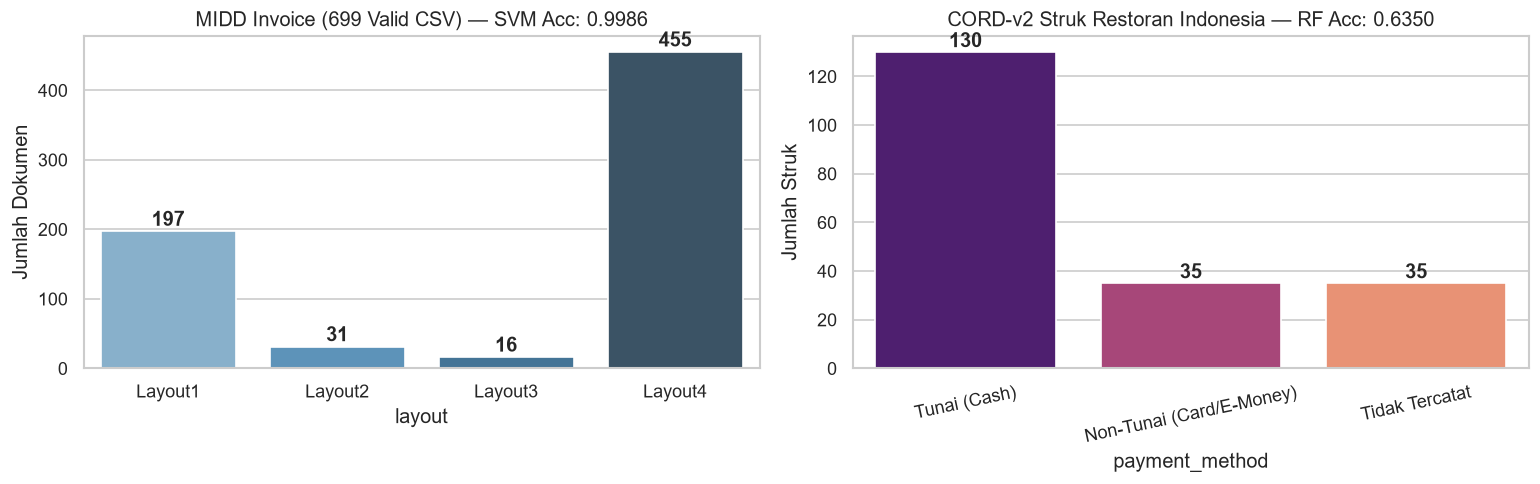

,IOB_Tag,Frekuensi
0,I-GSTL,2662
1,I-INV_NO,1539
2,B-GSTL,1363
3,I-INV_L,1352
4,I-BUY_N,1284
5,I-SUPP_N,710
6,B-SUPP_N,701
7,B-BUY_N,698
8,B-INV_L,696
9,B-INV_DT,695


In [5]:
# Pre-processing, EDA C, Feature Extraction C, Modeling C, & Evaluation C
# C1. MIDD Multi-Layout Invoice Document Dataset (IOB CSV)
midd_root = PATHS['midd_dir']
doc_rows, tag_counts = [], {}
for layout_dir in sorted(midd_root.iterdir()):
    if not layout_dir.is_dir():
        continue
    for csv_f in sorted(layout_dir.glob('*.csv')):
        try:
            d = pd.read_csv(csv_f, on_bad_lines='skip')
            if 'Text' not in d.columns or 'Tag' not in d.columns:
                continue
            toks = d['Text'].fillna('').astype(str).tolist()
            tags = d['Tag'].fillna('O').astype(str).str.strip().tolist()
            for t in tags:
                if t != 'O':
                    tag_counts[t] = tag_counts.get(t, 0) + 1
            doc_rows.append({'file': csv_f.name, 'layout': layout_dir.name, 'n_tokens': len(toks), 'n_entity': sum(t != 'O' for t in tags), 'text_joined': ' '.join(toks[:250])})
        except Exception:
            continue

df_midd = pd.DataFrame(doc_rows)
X_midd = TfidfVectorizer(max_features=1200, stop_words='english').fit_transform(df_midd['text_joined'])
y_midd = df_midd['layout'].to_numpy(dtype=str)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred_svm = cross_val_predict(LinearSVC(random_state=42, dual='auto'), X_midd, y_midd, cv=skf)
pred_rf = cross_val_predict(RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), X_midd, y_midd, cv=skf)
print(f'[MIDD Invoice] Valid CSV: {len(df_midd)} | Avg Token: {df_midd["n_tokens"].mean():.1f} | LinearSVC Acc: {accuracy_score(y_midd, pred_svm):.4f} (F1: {f1_score(y_midd, pred_svm, average="macro"):.4f}) | RF Acc: {accuracy_score(y_midd, pred_rf):.4f}')

# C2. CORD-v2 Struk Restoran Indonesia (200 Struk dari HF iqbal-rizanta/cord-v2-bucket)
df_cord['has_digital_payment'] = (df_cord['payment_method'] == 'Non-Tunai (Card/E-Money)').astype(int)
cord_feats = ['num_menu_items', 'ocr_line_count', 'ocr_word_count', 'has_tax', 'has_service_charge', 'has_discount']
X_cord = df_cord[cord_feats].astype(float).fillna(0).values
y_cord = df_cord['has_digital_payment'].values
pred_cord = cross_val_predict(RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42, class_weight='balanced'), X_cord, y_cord, cv=skf)
valid_idr = df_cord['total_price_idr'].dropna()
valid_idr = valid_idr[(valid_idr >= 1000) & (valid_idr <= 10_000_000)]
print(f'[CORD-v2 Struk] Total: {len(df_cord)} struk | Median Rp {int(valid_idr.median()):,} | Mean Rp {int(valid_idr.mean()):,} | RF Digital Payment Acc: {accuracy_score(y_cord, pred_cord):.4f} (F1: {f1_score(y_cord, pred_cord, average="macro"):.4f})')

# C3. 3 Dokumen PDF Perizinan Lokal
display(df_dok_pdf[['dok_id', 'file_name', 'pages', 'file_size_kb', 'institusi']])

# Visualisasi Cabang C (MIDD Layout & CORD-v2 Metode Bayar)
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2))
l_cnt = df_midd['layout'].value_counts().sort_index()
sns.barplot(x=l_cnt.index, y=l_cnt.values, hue=l_cnt.index, palette='Blues_d', legend=False, ax=axes[0])
axes[0].set_title(f'MIDD Invoice ({len(df_midd)} Valid CSV) — SVM Acc: {accuracy_score(y_midd, pred_svm):.4f}')
axes[0].set_ylabel('Jumlah Dokumen')
for i, v in enumerate(l_cnt.values):
    axes[0].text(i, v + 8, str(v), ha='center', fontweight='bold')

p_cnt = df_cord['payment_method'].value_counts()
sns.barplot(x=p_cnt.index, y=p_cnt.values, hue=p_cnt.index, palette='magma', legend=False, ax=axes[1])
axes[1].set_title(f'CORD-v2 Struk Restoran Indonesia — RF Acc: {accuracy_score(y_cord, pred_cord):.4f}')
axes[1].set_ylabel('Jumlah Struk'); axes[1].tick_params(axis='x', rotation=12)
for i, v in enumerate(p_cnt.values):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Inferences C: Top-10 Entitas IOB Invoice MIDD
top_tags = pd.DataFrame(sorted(tag_counts.items(), key=lambda x: x[1], reverse=True)[:10], columns=['IOB_Tag', 'Frekuensi'])
display(top_tags)

## Titik Temu — Analysis & Visualization: Spatial BDA 6 Kecamatan & Komparasi Repeat vs Modifikasi [Flowchart Page 4]

,Modalitas_Tahap,Sumber_Dataset,Metode_Utama,Metrik_Utama
0,1. Repeat Jurnal Utama (Tabular 48 SWK),"Satu Data Surabaya (Selayanti et al., 2024)",AHC Complete Linkage (k=3),Cophenetic = 0.8566 | Silhouette = 0.4893 (Pap...
1,2A. Modifikasi Gambar + Teks/Numerik UMKM,549 Foto (279.99 MB) + 385 UMKM + 1.164 Ulasan...,"K-Means, Autoencoder, RF, Gradient Boosting, P...","GB Acc = 0.9792, F1 = 0.9533 | K-Means Sil = 0..."
2,2B. Gambar Masakan Indonesia Serupa (Padang Cu...,"HF fahmindra/padang-cuisine (ODbL, 993 foto, 9...",HSV/Lab Spatial Pyramid + Sobel Texture + Rand...,"Test Acc = 0.6333, Macro-F1 = 0.6191 (9 Kelas ..."
3,3A. Dokumen Invoice (MIDD - 708 CSV IOB),MIDD Zenodo 10.5281/zenodo.5113009 (Baviskar e...,TF-IDF + LinearSVC & Random Forest (4-Layout C...,"SVM Acc = 0.9986, F1 = 0.9991 | RF Acc = 0.9986"
4,3B. Dokumen Struk Indonesia (CORD-v2),"CORD-v2 (Park et al., 2019; HF iqbal-rizanta/c...",Receipt Metadata Feature Extraction + RF Payme...,"Acc = 0.6350, F1 = 0.4961 | Median Struk Rp 48..."


,kecamatan,total_umkm,qris_rate,ojol_rate,avg_maturity_score,digital_gap_index,rekomendasi_intervensi
0,Gubeng,172,14.53,9.30,11.88,88.12,Prioritas Tinggi (Pendampingan Intensif QRIS &...
1,Gunung Anyar,50,16.00,22.00,14.75,85.25,Prioritas Tinggi (Pendampingan Intensif QRIS &...
2,Tenggilis Mejoyo,42,26.19,14.29,16.80,83.20,Prioritas Tinggi (Pendampingan Intensif QRIS &...
3,Rungkut,59,28.81,18.64,17.65,82.35,Prioritas Tinggi (Pendampingan Intensif QRIS &...
4,Sukolilo,35,31.43,20.00,19.91,80.09,Prioritas Tinggi (Pendampingan Intensif QRIS &...
5,Mulyorejo,27,44.44,22.22,23.97,76.03,Prioritas Menengah (Akselerasi POS Kasir Digital)


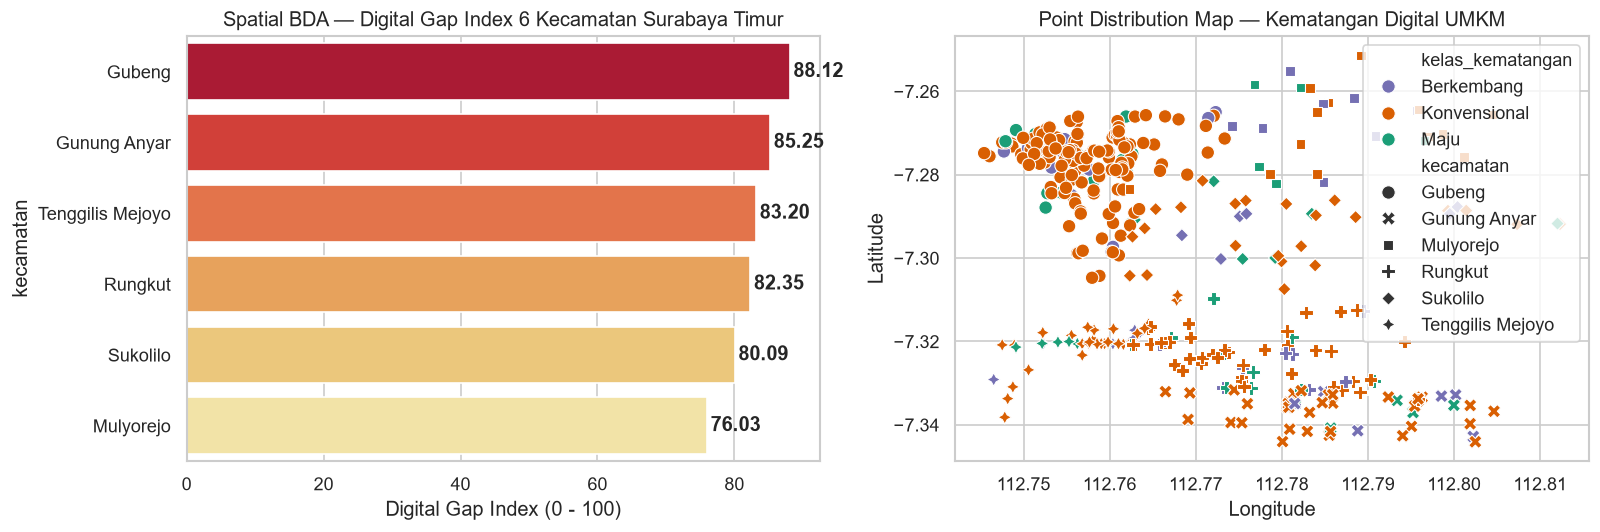

In [6]:
# 1. Tabel Komparasi Terpadu: Repeat Jurnal Utama vs Modifikasi 3 Modalitas (Dataset A, B, C)
df_comp = pd.read_csv(PATHS['modif_res'] / 'adjust_vs_repeat_multimodal_summary.csv')
display(df_comp)

# 2. Spatial BDA — Digital Gap Index 6 Kecamatan Surabaya Timur
df_gap = pd.read_csv(PATHS['bda_res'] / 'kecamatan_digital_gap.csv')
display(df_gap[['kecamatan', 'total_umkm', 'qris_rate', 'ojol_rate', 'avg_maturity_score', 'digital_gap_index', 'rekomendasi_intervensi']])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
sns.barplot(data=df_gap, x='digital_gap_index', y='kecamatan', hue='kecamatan', palette='YlOrRd_r', legend=False, ax=axes[0])
axes[0].set_title('Spatial BDA — Digital Gap Index 6 Kecamatan Surabaya Timur')
axes[0].set_xlabel('Digital Gap Index (0 - 100)')
for i, val in enumerate(df_gap['digital_gap_index']):
    axes[0].text(val + 0.5, i, f'{val:.2f}', va='center', fontweight='bold')

sns.scatterplot(
    data=df_feat, x='lon', y='lat', hue='kelas_kematangan', style='kecamatan',
    palette={'Konvensional': '#d95f02', 'Berkembang': '#7570b3', 'Maju': '#1b9e77'},
    s=65, ax=axes[1],
)
axes[1].set_title('Point Distribution Map — Kematangan Digital UMKM')
axes[1].set_xlabel('Longitude'); axes[1].set_ylabel('Latitude')
plt.tight_layout()
plt.show()